# Breast Cancer Prediction using Deep Learning
A neural network (TensorFlow/Keras) that classifies tumors from 5 cell-nucleus measurements.

**Dataset:** `Breast_cancer_data.csv` (569 samples) | **Target:** `diagnosis` (0 = malignant, 1 = benign in the Wisconsin dataset)

> For learning and research only, not a medical diagnosis.

## 1. Imports and configuration

In [1]:
import os, json, random
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, accuracy_score)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks

SEED = 42
DATA_PATH = "Breast_cancer_data.csv"
OUT_DIR = "outputs"
TARGET = "diagnosis"
os.makedirs(OUT_DIR, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
%matplotlib inline

I0000 00:00:1792776390.439090     108 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792776405.192951     108 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792776413.311951     108 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 2. Load and explore the data

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
display(df.describe().T)
print("Missing values:", df.isna().sum().sum())

Shape: (569, 6)


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0
1,20.57,17.77,132.90,1326.0,0.08474,0
2,19.69,21.25,130.00,1203.0,0.10960,0
3,11.42,20.38,77.58,386.1,0.14250,0
4,20.29,14.34,135.10,1297.0,0.10030,0


,count,mean,std,min,25%,50%,75%,max
mean_radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.7800,28.1100
mean_texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.8000,39.2800
mean_perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.1000,188.5000
mean_area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.7000,2501.0000
mean_smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.1053,0.1634
diagnosis,569.0,0.627417,0.483918,0.00000,0.00000,1.00000,1.0000,1.0000


Missing values: 0


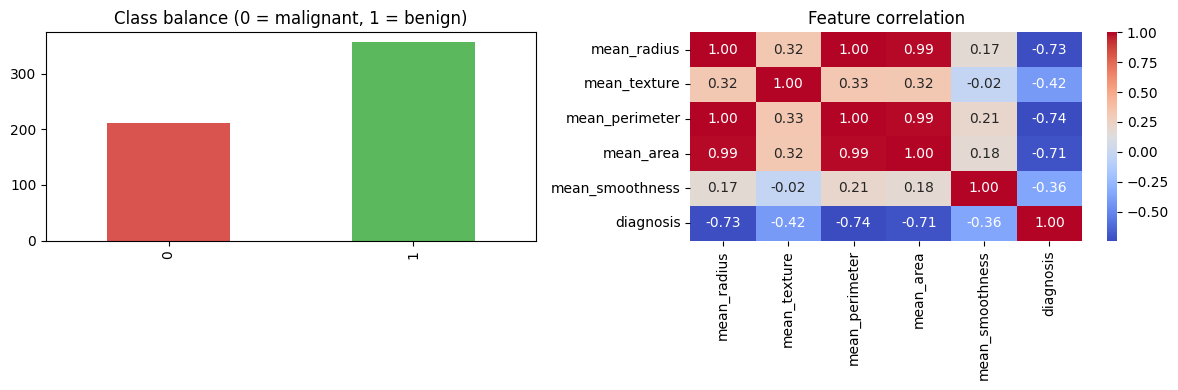

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df[TARGET].value_counts().sort_index().plot(kind="bar", ax=ax[0], color=["#d9534f", "#5cb85c"])
ax[0].set_title("Class balance (0 = malignant, 1 = benign)"); ax[0].set_xlabel("")
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1])
ax[1].set_title("Feature correlation")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/correlation_heatmap.png", dpi=150); plt.show()

Radius, perimeter and area are almost perfectly correlated, which is expected since they are geometrically related.

## 3. Split (stratified) and scale
The scaler is fit on the **training set only** to avoid data leakage.

In [4]:
X = df.drop(columns=[TARGET]).values.astype("float32")
y = df[TARGET].values.astype("float32")
feature_names = df.drop(columns=[TARGET]).columns.tolist()

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

scaler = StandardScaler().fit(X_train)
X_train, X_val, X_test = (scaler.transform(a) for a in (X_train, X_val, X_test))
print(f"Train {len(X_train)} | Val {len(X_val)} | Test {len(X_test)}")

cw = compute_class_weight("balanced", classes=np.array([0., 1.]), y=y_train)
class_weight = {0: cw[0], 1: cw[1]}
print("Class weights:", class_weight)

Train 398 | Val 85 | Test 86
Class weights: {0: np.float64(1.3445945945945945), 1: np.float64(0.796)}


## 4. Build the neural network

In [5]:
def build_model(n_features):
    model = keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(1e-3)),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(32, activation="relu", kernel_regularizer=regularizers.l2(1e-3)),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc"),
                 keras.metrics.Precision(name="precision"),
                 keras.metrics.Recall(name="recall")],
    )
    return model

model = build_model(X_train.shape[1])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,201 (12.50 KB)

 Non-trainable params: 192 (768.00 B)

## 5. Train
Early stopping halts training when validation loss stops improving, and the learning rate is reduced on plateaus.

In [6]:
cbs = [
    callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=8, min_lr=1e-5),
    callbacks.ModelCheckpoint(f"{OUT_DIR}/best_model.keras", monitor="val_loss", save_best_only=True),
]
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=200, batch_size=32, class_weight=class_weight,
                    callbacks=cbs, verbose=0)
print(f"Stopped after {len(history.history['loss'])} epochs")

Stopped after 45 epochs


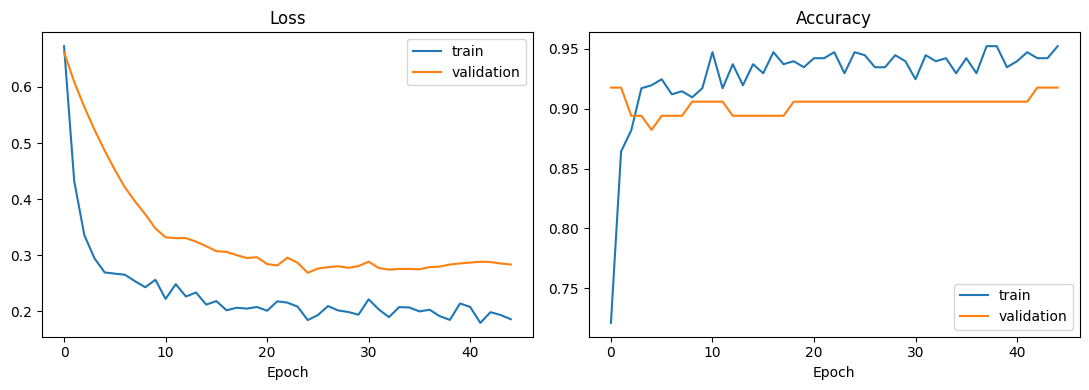

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, m in zip(ax, ["loss", "accuracy"]):
    a.plot(history.history[m], label="train")
    a.plot(history.history[f"val_{m}"], label="validation")
    a.set_title(m.capitalize()); a.set_xlabel("Epoch"); a.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/training_curves.png", dpi=150); plt.show()

## 6. Evaluate on the held-out test set

In [8]:
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
print(f"Test accuracy: {acc:.4f} | ROC-AUC: {auc:.4f}\n")
print(classification_report(y_test, y_pred, target_names=["Malignant (0)", "Benign (1)"]))

Test accuracy: 0.8721 | ROC-AUC: 0.9659

               precision    recall  f1-score   support

Malignant (0)       0.77      0.94      0.85        32
   Benign (1)       0.96      0.83      0.89        54

     accuracy                           0.87        86
    macro avg       0.86      0.89      0.87        86
 weighted avg       0.89      0.87      0.87        86



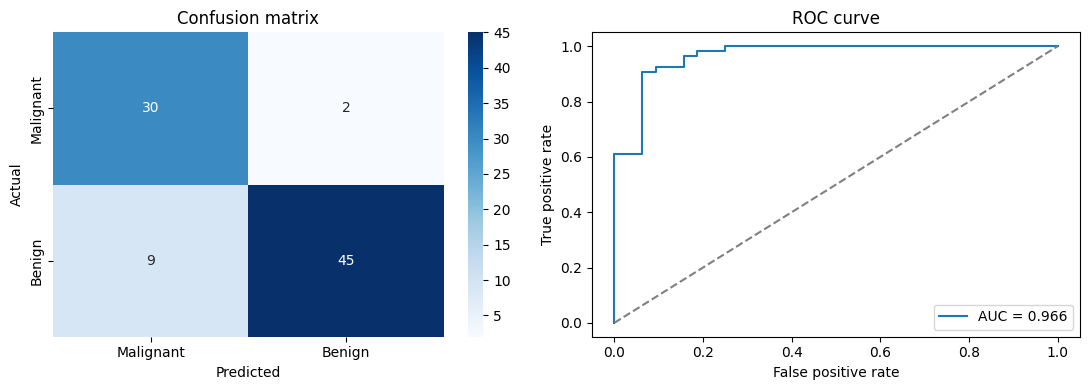

In [9]:
cm = confusion_matrix(y_test, y_pred)
fpr, tpr, _ = roc_curve(y_test, y_prob)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=["Malignant", "Benign"], yticklabels=["Malignant", "Benign"])
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual"); ax[0].set_title("Confusion matrix")
ax[1].plot(fpr, tpr, label=f"AUC = {auc:.3f}")
ax[1].plot([0, 1], [0, 1], "--", color="gray")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
ax[1].set_title("ROC curve"); ax[1].legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/confusion_matrix_roc.png", dpi=150); plt.show()

## 7. Feature importance (permutation)
Each feature is shuffled in the test set; the bigger the accuracy drop, the more the model relies on it.

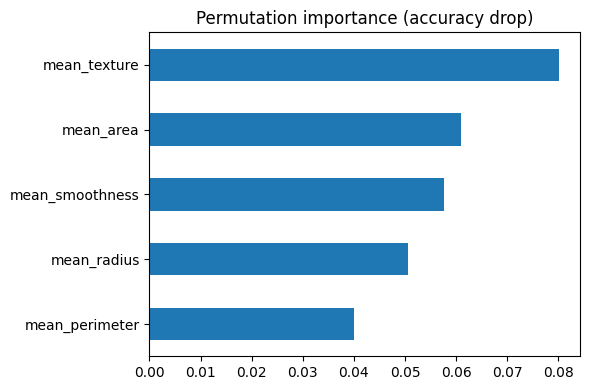

In [10]:
rng = np.random.default_rng(SEED)
imp = {}
for i, name in enumerate(feature_names):
    drops = []
    for _ in range(20):
        Xp = X_test.copy(); Xp[:, i] = rng.permutation(Xp[:, i])
        p = (model.predict(Xp, verbose=0).ravel() >= 0.5).astype(int)
        drops.append(acc - accuracy_score(y_test, p))
    imp[name] = np.mean(drops)
pd.Series(imp).sort_values().plot(kind="barh", figsize=(6, 4),
                                  title="Permutation importance (accuracy drop)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/feature_importance.png", dpi=150); plt.show()

## 8. Save the model and predict on a new sample

In [11]:
model.save(f"{OUT_DIR}/breast_cancer_model.keras")
joblib.dump(scaler, f"{OUT_DIR}/scaler.pkl")
with open(f"{OUT_DIR}/metrics.json", "w") as f:
    json.dump({"test_accuracy": float(acc), "test_roc_auc": float(auc),
               "confusion_matrix": cm.tolist()}, f, indent=2)

# order: mean_radius, mean_texture, mean_perimeter, mean_area, mean_smoothness
sample = np.array([[17.99, 10.38, 122.8, 1001.0, 0.1184]], dtype="float32")
prob = float(model.predict(scaler.transform(sample), verbose=0)[0, 0])
print(f"P(benign) = {prob:.3f}  ->  {'Benign' if prob >= 0.5 else 'Malignant'}")

P(benign) = 0.026  ->  Malignant


## 9. Notes
- The test set is small (86 samples), so metrics vary with the random seed. Consider stratified k-fold cross-validation for a sturdier estimate.
- Only 5 features are used, so accuracy is lower than with the full 30-feature Wisconsin dataset.
- Verify that 0 = malignant and 1 = benign matches your data source.